# 02 — Мультимодальна інженерія ознак, AutoFE, пастка витоку і відбір

План (ТЗ ЛР2, п. 2.1):
0. Дані, розбиття 70/30, протокол верифікації на вихідному конвеєрі.
1. **Крок 1** — ручні ознаки (`src/features.py`): часові, взаємодії, OOF-WoE → **Експеримент 2**.
2. **Крок 2** — мультимодальна екстракція (`src/extraction.py`): текст + зображення Amazon Reviews 2023, перевірка інформативності.
3. **Крок 3** — Featuretools DFS, графік «до/після», повторна перевірка захищених ознак.
4. **Крок 4** — п'ять експериментів, **пастка витоку** (Експеримент 4), DPR/EOR.
5. **Крок 5** — базова статистика → Filter → Hybrid (SFS) → Embedded → Tree (`src/selection.py`).

> SHAP / LIME не використовуються (умова ТЗ). Витік допускається **лише** в Експерименті 4.


In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 60)
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

ACCENT, SECOND, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d0cfca", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
MODELS = {"LR": lambda: LogisticRegression(max_iter=1000),
          "RF": lambda: RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)}
FAMILY = {"LR": "lr", "RF": "rf"}   # LR → config_lr*.yaml (additive), RF → config_rf*.yaml (partitioning)

## 0. Дані та розбиття

In [2]:
from src.data import load_data_config, load_raw, load_dataset, split_xy
dc = load_data_config()
raw = load_raw(dc)
df = load_dataset(dc)          # дедуплікація → MCAR-пропуски (config/data.yaml)
X, y = split_xy(df, dc)
print(f"Сирий набір: {raw.shape}, після дедуплікації: {df.shape}  (прибрано {len(raw) - len(df)} точних копій)")
print(f"Частка відтоку: {y.mean():.4f}")

# ЄДИНЕ розбиття для всіх експериментів: 70/30, стратифіковано (ТЗ, п. 4.4)
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.3, stratify=y, random_state=42)
X_train, X_test, y_train, y_test = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
train_ids = set(X_train[dc["id_column"]])
print(f"train {X_train.shape}, test {X_test.shape}")

Сирий набір: (5630, 20), після дедуплікації: (5074, 20)  (прибрано 556 точних копій)
Частка відтоку: 0.1657
train (3551, 19), test (1523, 19)


In [3]:
# Протокол верифікації ЛР1 на вихідному конвеєрі — ДО будь-яких змін (ТЗ, «Порядок дій», п. 1)
import os
os.chdir(ROOT)
import run_verification as rv
for path in ("config/config_lr.yaml", "config/config_rf.yaml"):
    rv.test_idempotent(path); rv.test_protected_excluded(path)
    print(f"{path}: перевірки пройдено")

config/config_lr.yaml: перевірки пройдено
config/config_rf.yaml: перевірки пройдено


## Експеримент 0 — евристичне правило з ЛР1 (без навчання)

У ЛР1 (5 630 рядків, з дублікатами): **Accuracy 0.699, Recall 0.848, Precision 0.341**. Для порівнюваності з
експериментами 1–4 рахуємо його ROC-AUC на тій самій тестовій підвибірці. Для бінарного прогнозу ROC-AUC = (TPR + TNR) / 2.


In [4]:
from sklearn.metrics import accuracy_score, recall_score, precision_score
from src.evaluation import heuristic_predict
h_all, h_test = heuristic_predict(X), heuristic_predict(X_test)
exp0 = {"Accuracy (весь набір)": accuracy_score(y, h_all), "Recall (весь набір)": recall_score(y, h_all),
        "Precision (весь набір)": precision_score(y, h_all), "ROC-AUC (test)": roc_auc_score(y_test, h_test)}
pd.Series(exp0).round(3).to_frame("Експеримент 0")

,Експеримент 0
Accuracy (весь набір),0.698
Recall (весь набір),0.844
Precision (весь набір),0.336
ROC-AUC (test),0.740


## 1. Крок 1 — ручний дизайн ознак

Конструктори з секції `feature_engineering` (`config/config_*_fe.yaml`), усі безстанові:

| Категорія | Ознака | Що це |
|---|---|---|
| А. Часова | `TenureStage` | етап життєвого циклу: 0 новий (≤1 міс.), 1 ранній (≤5), 2 постійний (≤12), 3 лояльний |
| А/Б | `RecencyRatio` | днів з останнього замовлення / (стаж у днях + 1) — «свіжість» відносно стажу |
| Б. Взаємодії | `CashbackPerOrder`, `CouponPerOrder`, `OrdersPerTenureMonth` | відношення з ε (захист від ділення на 0) |
| В. Висока кардинальність | `Segment` | схрещення категорія × сімейний стан × задоволеність × пристрій → кодується **OOF-WoE** |

Дат у наборі немає, тому циклічне sin/cos для клієнтської таблиці не застосовне; воно використане для часу відгуків (Крок 2).


In [5]:
from src.pipeline import ExtendedPipelineBuilder
fe_builder = ExtendedPipelineBuilder(ROOT / "config" / "config_lr_fe.yaml")
construct = fe_builder.build().named_steps["construct"]
new_cols = ["TenureStage", "RecencyRatio", "CashbackPerOrder", "CouponPerOrder", "OrdersPerTenureMonth", "Segment"]
sample = construct.fit_transform(X_train)[["Tenure", "DaySinceLastOrder", "OrderCount"] + new_cols]
print("Кардинальність Segment на train:", sample["Segment"].nunique())
sample.head()

Кардинальність Segment на train: 164


,Tenure,DaySinceLastOrder,OrderCount,TenureStage,RecencyRatio,CashbackPerOrder,CouponPerOrder,OrdersPerTenureMonth,Segment
171,NaN,0.0,1.0,NaN,NaN,114.198858,0.000000,NaN,Mobile Phone | Single | 3 | Mobile Phone
4197,16.0,1.0,2.0,3.0,0.002079,142.459288,NaN,0.117647,Grocery | Single | 1 | Mobile Phone
1559,23.0,6.0,1.0,3.0,0.008683,295.167048,0.999990,0.041667,Others | Married | 1 | Mobile Phone
5019,12.0,1.0,2.0,2.0,0.002770,76.789616,0.999995,0.153846,NA | Single | 5 | Mobile Phone
2679,19.0,11.0,NaN,3.0,0.019264,NaN,NaN,NaN,Grocery | Divorced | 2 | Mobile Phone


**Навіщо OOF-WoE.** Звичайний WoE (ЛР1) кодує кожен рядок train вагою, порахованою *з урахуванням його ж мітки*.
Для рідкісних сегментів це майже пряма підстановка цілі: на train зв'язок завищений, на test — ні.
OOF-WoE кодує кожен фолд вагами з решти фолдів.


In [6]:
from src.features import WoEEncoder, OOFWoEEncoder
seg_tr = construct.fit_transform(X_train)[["Segment"]]
seg_te = construct.transform(X_test)[["Segment"]]
rows = []
for name, enc in [("WoE (ЛР1)", WoEEncoder()), ("OOF-WoE (ЛР2)", OOFWoEEncoder())]:
    z_tr = enc.fit_transform(seg_tr, y_train)["Segment"]
    z_te = enc.transform(seg_te)["Segment"]
    rows.append({"кодувальник": name, "ROC-AUC на train": roc_auc_score(y_train, z_tr),
                 "ROC-AUC на test": roc_auc_score(y_test, z_te)})
pd.DataFrame(rows).round(3)

,кодувальник,ROC-AUC на train,ROC-AUC на test
0,WoE (ЛР1),0.777,0.699
1,OOF-WoE (ЛР2),0.702,0.699


Звичайний WoE на train обіцяє більше, ніж дає на test (перенавчання на шумі рідкісних сегментів);
OOF-WoE дає на train чесну, близьку до test оцінку. Саме OOF-значення бачить модель під час навчання.

### Експеримент 1 (Baseline) і Експеримент 2 (Manual FE)


In [7]:
results = {}
def fit_eval(name, model_key, prep, Xtr, Xte):
    pipe = Pipeline([("prep", prep), ("model", MODELS[model_key]())]).fit(Xtr, y_train)
    proba = pipe.predict_proba(Xte)[:, 1]
    results[(name, model_key)] = roc_auc_score(y_test, proba)
    return pipe, proba

fitted, probas = {}, {}
for m, f in FAMILY.items():
    for name, cfg_name in [("1. Baseline", f"config_{f}.yaml"), ("2. Manual FE", f"config_{f}_fe.yaml")]:
        fitted[(name, m)], probas[(name, m)] = fit_eval(name, m, ExtendedPipelineBuilder(ROOT / "config" / cfg_name).build(),
                                                       X_train, X_test)
pd.Series(results).unstack().round(4)

,LR,RF
1. Baseline,0.8690,0.9621
2. Manual FE,0.8767,0.9566


## 2. Крок 2 — мультимодальна екстракція (Amazon Reviews 2023)

In [8]:
from src.extraction import (load_multimodal_config, prepare_linked_reviews, review_texts, review_features,
                            TextExtractor, ImageExtractor, run_dfs)
mm = load_multimodal_config()
reviews = prepare_linked_reviews(df, mm)     # корпус → прив'язка → фото (кеш у data/processed/)
per_cust = reviews.groupby(dc["id_column"]).size()
print(f"Відгуків: {len(reviews)}, клієнтів: {reviews[dc['id_column']].nunique()}, відгуків на клієнта: "
      f"{per_cust.min()}–{per_cust.max()} (середнє {per_cust.mean():.2f})")
print("Кожен відгук корпусу використано один раз:", reviews["corpus_index"].is_unique)
print("За категоріями Amazon:", reviews["source_category"].value_counts().to_dict())
m_ = reviews.merge(df[[dc["id_column"], "SatisfactionScore"]], on=dc["id_column"])
print(f"Оцінка відгуку = SatisfactionScore клієнта: {(m_.rating == m_.SatisfactionScore).mean():.1%} (за побудовою прив'язки)")
reviews[["review_id", dc["id_column"], "source_category", "rating", "title", "image_path"]].head()

Відгуків: 12026, клієнтів: 5074, відгуків на клієнта: 1–5 (середнє 2.37)
Кожен відгук корпусу використано один раз: True
За категоріями Amazon: {'Electronics': 4177, 'Cell_Phones_and_Accessories': 3568, 'Clothing_Shoes_and_Jewelry': 2082, 'Grocery_and_Gourmet_Food': 1192, 'Home_and_Kitchen': 1007}
Оцінка відгуку = SatisfactionScore клієнта: 100.0% (за побудовою прив'язки)


,review_id,CustomerID,source_category,rating,title,image_path
0,0,51697,Cell_Phones_and_Accessories,4,Ok,NaN
1,1,52839,Cell_Phones_and_Accessories,3,"Cute Design, But Scratches Easily",NaN
2,2,52839,Grocery_and_Gourmet_Food,3,Ok,NaN
3,3,52839,Grocery_and_Gourmet_Food,3,Good but...,NaN
4,4,51599,Electronics,5,A little Gem of a World Band Receiver,NaN


**Як прив'язано (імітація зв'язку).** Корпус не має спільного ключа з клієнтами (ТЗ, розділ 3), тому кожен клієнт отримує
`min(OrderCount, 5)` відгуків з категорії Amazon, що відповідає його `PreferedOrderCat`, з оцінкою, найближчою до `SatisfactionScore`;
кожен відгук — лише одному клієнту. Ціль `Churn` не використовується.

**TextExtractor навчається тільки на відгуках train-клієнтів** (залежний від даних: словник TF-IDF + SVD), застосовується до всіх.
`ImageExtractor` (GLCM) безстановий.


In [9]:
reviews_train = reviews[reviews[dc["id_column"]].isin(train_ids)]
text_ex = TextExtractor(**mm["extraction"]["text"]).fit(review_texts(reviews_train).to_frame())
image_ex = ImageExtractor(levels=mm["extraction"]["image"]["levels"])
rev_feat = review_features(reviews, text_ex, image_ex, mm)       # один рядок — один відгук
print("Текст (порожні входи):", text_ex.stats_)
print("Зображення:", image_ex.stats_)
rev_feat.describe().T[["count", "mean", "min", "max"]].round(3)

Текст (порожні входи): {'fit_rows': 8458, 'fit_empty': 2, 'transform_rows': 12026, 'transform_empty': 2}
Зображення: {'rows': 12026, 'no_image': 11320, 'failed': 0, 'ok': 706}


,count,mean,min,max
review_id,12026.0,6012.500,0.000,12025.000
CustomerID,12026.0,52959.775,50001.000,55630.000
rating,12026.0,3.035,1.000,5.000
text_len,12026.0,71.137,0.000,1805.000
text_svd_0,12024.0,0.188,0.000,0.510
text_svd_1,12024.0,0.006,-0.159,0.877
text_svd_2,12024.0,0.002,-0.364,0.677
text_svd_3,12024.0,-0.003,-0.352,0.762
text_svd_4,12024.0,-0.007,-0.444,0.501
img_contrast,706.0,9.157,0.222,121.639


In [10]:
# Топ-слова кожної SVD-компоненти — що «бачить» текстовий блок
terms = np.array(text_ex.vectorizer_.get_feature_names_out())
pd.DataFrame({f"text_svd_{i}": terms[np.argsort(-comp)[:8]] for i, comp in enumerate(text_ex.svd_.components_)})

,text_svd_0,text_svd_1,text_svd_2,text_svd_3,text_svd_4
0,br,stars,good,great,good
1,good,great,quality,case,phone
2,great,good,product,phone,product
3,like,works,flavor,love,case
4,phone,product,taste,works,screen
5,case,nice,size,product,protector
6,just,love,like,perfect,br
7,use,quality,price,quality,work


### Перевірка інформативності блоку (до AutoFE)

Логістична регресія (statsmodels) **на train**: базові ознаки ЛР1 vs базові + агрегований мультимодальний блок
(середні по відгуках клієнта: 5 SVD-компонент тексту, 4 GLCM-ознаки, частка відгуків із фото).
Порівнюємо AIC (менше — краще), псевдо-R² Макфаддена і тест відношення правдоподібностей.


In [11]:
import statsmodels.api as sm
from scipy.stats import chi2
from sklearn.preprocessing import StandardScaler
from src.dynamic_pipeline_builder import AdaptiveImputer

base_prep = ExtendedPipelineBuilder(ROOT / "config" / "config_lr.yaml").build()
B_tr = base_prep.fit_transform(X_train, y_train)

def block_for(extractor_components):
    ex = TextExtractor(max_features=500, n_components=extractor_components, random_state=42)
    ex.fit(review_texts(reviews_train).to_frame())
    rf_ = review_features(reviews, ex, image_ex, mm)
    cols = [c for c in rf_.columns if c.startswith(("text_svd_", "img_"))] + ["has_image"]
    agg = rf_.groupby(dc["id_column"])[cols].mean()
    blk = X_train[[dc["id_column"]]].join(agg, on=dc["id_column"]).drop(columns=dc["id_column"])
    imp = AdaptiveImputer(policy=fe_builder.config["imputation_policy"]["numeric"]).fit(blk)
    return StandardScaler().fit_transform(imp.transform(blk))

def logit(Z):
    return sm.Logit(y_train.to_numpy(), sm.add_constant(np.asarray(Z, dtype=float))).fit(disp=0, maxiter=200)

m0 = logit(B_tr)
rows = [{"модель": "базові ознаки ЛР1", "n_features": B_tr.shape[1], "AIC": m0.aic, "pseudo_R2": m0.prsquared, "LR-test p": np.nan}]
for k in (5, 10, 20):
    Z = np.hstack([B_tr, block_for(k)])
    m1 = logit(Z)
    lr_stat = 2 * (m1.llf - m0.llf)
    rows.append({"модель": f"+ мультимодальний блок (SVD={k})", "n_features": Z.shape[1], "AIC": m1.aic,
                 "pseudo_R2": m1.prsquared, "LR-test p": chi2.sf(lr_stat, Z.shape[1] - B_tr.shape[1])})
informativeness = pd.DataFrame(rows)
informativeness.round(4)

,модель,n_features,AIC,pseudo_R2,LR-test p
0,базові ознаки ЛР1,17,1950.9844,0.3998,NaN
1,+ мультимодальний блок (SVD=5),31,1960.2301,0.4038,0.5460
2,+ мультимодальний блок (SVD=10),36,1965.9737,0.4052,0.5891
3,+ мультимодальний блок (SVD=20),46,1979.8665,0.4071,0.7711


**Висновок.** Приріст pseudo-R² і зміна AIC — дуже малі, тест відношення правдоподібностей не показує значущого внеску
блоку. Збільшення `n_components` (5 → 10 → 20) не допомагає. Це очікувано: корпус — **паралельний** (інші люди, інший магазин),
а прив'язка передає лише вже наявну в таблиці інформацію (категорію і задоволеність). Параметри лишаємо дефолтними (SVD = 5)
і фіксуємо: синтез поверх цього блоку здебільшого роздуває простір шумом — це підтвердять експерименти 3–4 і відбір.


## 3. Крок 3 — AutoFE (Featuretools DFS)

In [12]:
fm, feature_defs = run_dfs(df, rev_feat, mm)       # EntitySet: clients (1) — reviews (N)
n_client_in, n_review_in = len(mm["dfs"]["client_columns"]), len(mm["dfs"]["review_columns"])
dfs_counts = pd.Series({
    "вхід DFS: колонки клієнта": n_client_in,
    "вхід DFS: колонки відгуку": n_review_in,
    "кандидати DFS (max_depth=2, без обмежень)": fm.attrs["n_candidates"],
    "залишено після обмеження (нові ознаки)": fm.shape[1],
})
dfs_counts.to_frame("кількість")

,кількість
вхід DFS: колонки клієнта,8
вхід DFS: колонки відгуку,16
"кандидати DFS (max_depth=2, без обмежень)",2234
залишено після обмеження (нові ознаки),110


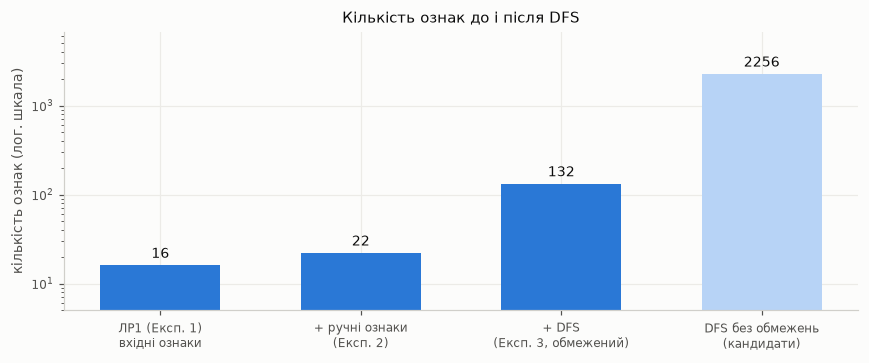

,ознак
ЛР1 (Експ. 1) вхідні ознаки,16
+ ручні ознаки (Експ. 2),22
"+ DFS (Експ. 3, обмежений)",132
DFS без обмежень (кандидати),2256


In [13]:
space = pd.Series({
    "ЛР1 (Експ. 1)\nвхідні ознаки": sum(len(v) for v in ExtendedPipelineBuilder(ROOT / "config" / "config_lr.yaml").config["features"].values()),
    "+ ручні ознаки\n(Експ. 2)": sum(len(v) for v in fe_builder.config["features"].values()),
    "+ DFS\n(Експ. 3, обмежений)": sum(len(v) for v in fe_builder.config["features"].values()) + fm.shape[1],
    "DFS без обмежень\n(кандидати)": sum(len(v) for v in fe_builder.config["features"].values()) + fm.attrs["n_candidates"],
})
fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(space.index, space.values, color=[ACCENT, ACCENT, ACCENT, "#b7d3f6"], width=0.6)
ax.set_yscale("log")
for b, v in zip(bars, space.values):
    ax.text(b.get_x() + b.get_width() / 2, v * 1.12, f"{v}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylabel("кількість ознак (лог. шкала)")
ax.set_ylim(5, space.max() * 3)
ax.set_title("Кількість ознак до і після DFS")
fig.tight_layout(); fig.savefig(REPORTS / "lab2_dfs_feature_count.png", bbox_inches="tight"); plt.show()
space.rename(lambda s: s.replace("\n", " ")).to_frame("ознак")

In [14]:
pd.Series([d.get_name() for d in feature_defs if d.get_name() in fm.columns]).sample(15, random_state=0).to_frame("приклади DFS-ознак")

,приклади DFS-ознак
85,WarehouseToHome / HourSpendOnApp
10,MAX(reviews.review_hour_sin)
75,Tenure / CashbackAmount
2,MAX(reviews.img_contrast)
24,MEAN(reviews.review_dow_sin)
101,NATURAL_LOGARITHM(MAX(reviews.img_homogeneity))
109,NATURAL_LOGARITHM(MEAN(reviews.text_len))
7,MAX(reviews.review_dow_cos)
16,MAX(reviews.text_svd_4)
91,NATURAL_LOGARITHM(DaySinceLastOrder)


### Повторна перевірка захищених ознак після DFS (CACE)

1. Чи потрапили `CityTier` / `Gender` у вхід DFS або в назви згенерованих ознак?
2. Протокол верифікації ЛР1 (`test_idempotent`, `test_protected_excluded`) на **згенерованій розширеній конфігурації**.
3. Чи не стали нові ознаки **проксі** захищених: розмір ефекту ε² (Kruskal–Wallis) між групами — на train.


In [15]:
protected = fe_builder.config["protected_attributes"]
dfs_inputs = set(mm["dfs"]["client_columns"]) | set(mm["dfs"]["review_columns"])
print("1) захищені у вході DFS:", dfs_inputs & set(protected) or "немає")
print("   захищені в назвах DFS-ознак:", [c for c in fm.columns if any(p in c for p in protected)] or "немає")

from src.pipeline import write_extended_config
dfs_policy = {"additive": ["yeo_johnson"], "partitioning": [{"winsorize": {"lower": 0.01, "upper": 0.99}}]}
header = ("ЗГЕНЕРОВАНО ноутбуком 02_multimodal_leakage.ipynb — не редагувати вручну.\n"
          "= config_{f}_fe.yaml + група multimodal_dfs (ознаки після мультимодальної екстракції та DFS).")
for f in ("lr", "rf"):
    write_extended_config(ROOT / "config" / f"config_{f}_fe.yaml", ROOT / "config" / "generated" / f"config_{f}_full.yaml",
                          "multimodal_dfs", fm.columns, "numeric", dfs_policy, header=header.format(f=f))
    write_extended_config(ROOT / "config" / f"config_{f}_fe.yaml", ROOT / "config" / "generated" / f"config_{f}_leaky.yaml",
                          "multimodal_dfs", fm.columns, "numeric", dfs_policy, replace_steps={"oof_woe": "woe"},
                          header=header.format(f=f) + "\nЕКСПЕРИМЕНТ 4 (навмисний витік): oof_woe замінено на woe.")
for f in ("lr", "rf"):
    for kind in ("full", "leaky"):
        p = f"config/generated/config_{f}_{kind}.yaml"
        rv.test_idempotent(p); rv.test_protected_excluded(p)
        print(f"2) {p}: перевірки пройдено")

1) захищені у вході DFS: немає
   захищені в назвах DFS-ознак: немає
2) config/generated/config_lr_full.yaml: перевірки пройдено


2) config/generated/config_lr_leaky.yaml: перевірки пройдено
2) config/generated/config_rf_full.yaml: перевірки пройдено
2) config/generated/config_rf_leaky.yaml: перевірки пройдено


In [16]:
from scipy.stats import kruskal
def epsilon_sq(values, groups):
    data = pd.DataFrame({"v": values, "g": groups}).dropna()
    parts = [g["v"].to_numpy() for _, g in data.groupby("g")]
    if len(parts) < 2 or min(len(p) for p in parts) < 2 or data["v"].nunique() < 2:
        return 0.0
    h, _ = kruskal(*parts)
    return (h - len(parts) + 1) / (len(data) - len(parts))

fm_train = fm.loc[X_train[dc["id_column"]]]
proxy = pd.DataFrame({
    "eps2_CityTier": [epsilon_sq(fm_train[c].to_numpy(), X_train["CityTier"].to_numpy()) for c in fm.columns],
    "eps2_Gender": [epsilon_sq(fm_train[c].to_numpy(), X_train["Gender"].to_numpy()) for c in fm.columns],
}, index=fm.columns)
print("3) DFS-ознак з ε² ≥ 0.01 (малий ефект і більше): CityTier —", int((proxy.eps2_CityTier >= 0.01).sum()),
      "| Gender —", int((proxy.eps2_Gender >= 0.01).sum()), "з", len(proxy))
base_eps = pd.Series({c: epsilon_sq(X_train[c].to_numpy(), X_train["CityTier"].to_numpy())
                      for c in mm["dfs"]["client_columns"]}, name="eps2_CityTier (сира колонка)")
display(proxy.sort_values("eps2_CityTier", ascending=False).head(8).round(4),
        base_eps.sort_values(ascending=False).round(4).to_frame())

3) DFS-ознак з ε² ≥ 0.01 (малий ефект і більше): CityTier — 3 | Gender — 0 з 110


,eps2_CityTier,eps2_Gender
NATURAL_LOGARITHM(CashbackAmount),0.0185,0.0010
OrderAmountHikeFromlastYear / CashbackAmount,0.0144,0.0022
CashbackAmount / OrderAmountHikeFromlastYear,0.0138,0.0023
Tenure / CashbackAmount,0.0076,0.0024
Tenure / WarehouseToHome,0.0070,0.0032
Tenure / HourSpendOnApp,0.0067,0.0038
MEAN(reviews.text_svd_3),0.0066,0.0003
CashbackAmount / Tenure,0.0060,0.0018


,eps2_CityTier (сира колонка)
CashbackAmount,0.0179
Tenure,0.0045
WarehouseToHome,0.0015
OrderAmountHikeFromlastYear,0.0007
OrderCount,0.0003
CouponUsed,-0.0001
HourSpendOnApp,-0.0003
DaySinceLastOrder,-0.0005


**Результат перевірки:**
1. Захищені ознаки не входять у DFS і не з'являються в назвах згенерованих ознак.
2. Протокол верифікації ЛР1 проходить на всіх розширених конфігураціях.
3. Лише кілька DFS-ознак мають *малий* зв'язок з `CityTier` (ε² ≈ 0.01–0.02), і всі вони — похідні від `CashbackAmount`, сира колонка
   якого має зв'язок того самого порядку (таблиця вище). Тобто DFS **не створив нового проксі**, а успадкував слабкий зв'язок кешбеку
   з рівнем міста. Зі статтю зв'язку немає. Головний проксі `CityTier` лишається той самий, що в ЛР1, — `PreferredPaymentMode`
   (V = 0.44, не DFS-ознака); ці кешбек-ознаки варто додати до списку на перевірку в ЛР3.

## 4. Крок 4 — експерименти 3 і 4


In [17]:
from src.selection import load_selection_config, make_filter, make_sfs
sel_cfg = load_selection_config()
X3 = X.join(fm, on=dc["id_column"])            # таблиця + DFS (мультимодальні агрегати всередині)
X3_train, X3_test = X3.iloc[idx_tr], X3.iloc[idx_te]

for m, f in FAMILY.items():
    full_prep = ExtendedPipelineBuilder(ROOT / "config" / "generated" / f"config_{f}_full.yaml").build()
    # 3: чесний відбір УСЕРЕДИНІ конвеєра — Filter і SFS навчаються лише на X3_train
    pipe = Pipeline([("prep", full_prep), ("filter", make_filter(sel_cfg)), ("sfs", make_sfs(sel_cfg)),
                     ("model", MODELS[m]())]).fit(X3_train, y_train)
    probas[("3. Extracted + AutoFE", m)] = pipe.predict_proba(X3_test)[:, 1]
    results[("3. Extracted + AutoFE", m)] = roc_auc_score(y_test, probas[("3. Extracted + AutoFE", m)])
    fitted[("3. Extracted + AutoFE", m)] = pipe
    # 3′: той самий простір без відбору — для контексту
    pipe_ns = Pipeline([("prep", ExtendedPipelineBuilder(ROOT / "config" / "generated" / f"config_{f}_full.yaml").build()),
                        ("model", MODELS[m]())]).fit(X3_train, y_train)
    results[("3′. те саме без відбору", m)] = roc_auc_score(y_test, pipe_ns.predict_proba(X3_test)[:, 1])
pd.Series(results).unstack().round(4)

,LR,RF
1. Baseline,0.8690,0.9621
2. Manual FE,0.8767,0.9566
3. Extracted + AutoFE,0.8286,0.9177
3′. те саме без відбору,0.8898,0.9256


### Експеримент 4 — навмисний витік (Leaky Pipeline)

Той самий простір ознак, але **параметри екстракції, кодування та відбору обчислюються на всьому наборі до розбиття**:

| Крок | Чесно (Експ. 3) | З витоком (Експ. 4) | Що протікає з test у train |
|---|---|---|---|
| TF-IDF + SVD | на відгуках train-клієнтів | на **всіх** відгуках | словник, IDF-ваги, напрямки SVD-компонент (без міток) |
| WoE (`Segment`, номінальні) | OOF на train | звичайний WoE на **всіх рядках з їхніми мітками** | частки відтоку в кожній категорії, включно з мітками test |
| SelectKBest + SFS | на train | на **всіх рядках з мітками** | які ознаки «працюють» на test |

Розбиття 70/30 відбувається **після** всього цього — на вже «забрудненій» матриці.


In [18]:
# --- Експеримент 4: тексти кодуються екстрактором, навченим на ВСІХ відгуках (train + test) ---
text_ex_leaky = TextExtractor(**mm["extraction"]["text"]).fit(review_texts(reviews).to_frame())   # ← ВИТІК №1 (TF-IDF/SVD бачать тексти test)
fm_leaky, _ = run_dfs(df, review_features(reviews, text_ex_leaky, image_ex, mm), mm)
X4 = X.join(fm_leaky, on=dc["id_column"])

for m, f in FAMILY.items():
    prep_leaky = ExtendedPipelineBuilder(ROOT / "config" / "generated" / f"config_{f}_leaky.yaml").build()
    prep_leaky.fit(X4, y)                     # ← ВИТІК №2 (ГОЛОВНИЙ): WoE рахує частки відтоку на ВСІХ рядках, включно з мітками test
    Z_all = prep_leaky.transform(X4)
    flt = make_filter(sel_cfg).fit(Z_all, y)  # ← ВИТІК №3: Filter обирає ознаки за мітками test
    Z_f = flt.transform(Z_all)
    sfs = make_sfs(sel_cfg).fit(Z_f, y.to_numpy())   # ← ВИТІК №3: SFS оцінює підмножини на CV, що включає test
    Z_s = sfs.transform(Z_f)
    Z_tr, Z_te = Z_s[idx_tr], Z_s[idx_te]     # розбиття — ПІСЛЯ всіх обчислень
    model = MODELS[m]().fit(Z_tr, y_train)
    probas[("4. Leaky Pipeline", m)] = model.predict_proba(Z_te)[:, 1]
    results[("4. Leaky Pipeline", m)] = roc_auc_score(y_test, probas[("4. Leaky Pipeline", m)])

table = pd.Series(results).unstack().reindex(["1. Baseline", "2. Manual FE", "3. Extracted + AutoFE",
                                              "3′. те саме без відбору", "4. Leaky Pipeline"])
table.loc["0. Non-ML Heuristic"] = exp0["ROC-AUC (test)"]
table = table.reindex(["0. Non-ML Heuristic"] + [i for i in table.index if not i.startswith("0.")])
table["Δ до Експ. 3 (LR)"] = table["LR"] - table.loc["3. Extracted + AutoFE", "LR"]
table.round(4).to_csv(REPORTS / "lab2_experiments.csv")
table.round(4)

,LR,RF,Δ до Експ. 3 (LR)
0. Non-ML Heuristic,0.7404,0.7404,-0.0882
1. Baseline,0.8690,0.9621,0.0404
2. Manual FE,0.8767,0.9566,0.0481
3. Extracted + AutoFE,0.8286,0.9177,0.0000
3′. те саме без відбору,0.8898,0.9256,0.0613
4. Leaky Pipeline,0.8599,0.9270,0.0313


In [19]:
# Перевірка ML Metric з ML Canvas ЛР1: Precision при Recall ≥ 0.80 (поріг підібрано на test → оцінка оптимістична; чесно — ЛР3)
from sklearn.metrics import precision_recall_curve
def precision_at_recall(y_true, score, min_recall=0.80):
    p, r, _ = precision_recall_curve(y_true, score)
    return p[r >= min_recall].max()
pd.DataFrame({m: {exp: precision_at_recall(y_test, probas[(exp, m)]) for exp in
                  ["1. Baseline", "2. Manual FE", "3. Extracted + AutoFE", "4. Leaky Pipeline"]} for m in MODELS}).round(3)

,LR,RF
1. Baseline,0.448,0.809
2. Manual FE,0.473,0.782
3. Extracted + AutoFE,0.359,0.563
4. Leaky Pipeline,0.418,0.594


Розрив між Експериментами 3 і 4 на нашому сегменті (~166 значень) помітний, але не катастрофічний. Причина — механізм WoE:
внесок власної мітки рядка у вагу його категорії ≈ 1 / (кількість рядків у категорії). Що вища кардинальність, то менші
категорії й тим сильніше «підглядання». Нижче — **симуляція**: модель лише на одній ознаці-сегменті, що схрещує дедалі більше колонок.


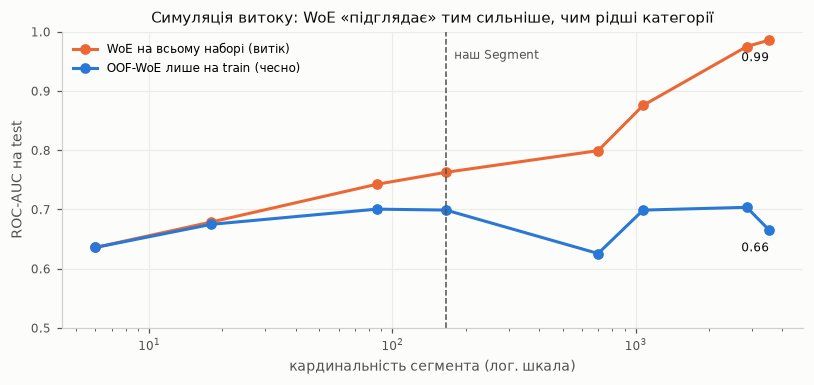

,k_columns,cardinality,honest_OOF,leaky_global_WoE
0,1,6,0.636,0.636
1,2,18,0.675,0.679
2,3,86,0.701,0.742
3,4,166,0.699,0.763
4,5,700,0.626,0.799
5,6,1072,0.699,0.876
6,7,2859,0.704,0.975
7,8,3539,0.665,0.986


In [20]:
from src.features import CategoryCrosser
Xa = construct.named_steps["aliases"].fit_transform(X)
order = ["PreferedOrderCat", "MaritalStatus", "SatisfactionScore", "PreferredLoginDevice",
         "NumberOfDeviceRegistered", "Complain", "NumberOfAddress", "HourSpendOnApp"]
sim = []
for k in range(1, len(order) + 1):
    seg = CategoryCrosser("seg", order[:k]).fit(Xa).transform(Xa)[["seg"]]
    enc = OOFWoEEncoder()
    z_tr = enc.fit_transform(seg.iloc[idx_tr], y_train); z_te = enc.transform(seg.iloc[idx_te])
    honest = roc_auc_score(y_test, LogisticRegression().fit(z_tr, y_train).predict_proba(z_te)[:, 1])
    z_all = WoEEncoder().fit(seg, y).transform(seg)                    # ← витік: WoE на всіх мітках
    leaky = roc_auc_score(y_test, LogisticRegression().fit(z_all.iloc[idx_tr], y_train).predict_proba(z_all.iloc[idx_te])[:, 1])
    sim.append({"k_columns": k, "cardinality": seg["seg"].nunique(), "honest_OOF": honest, "leaky_global_WoE": leaky})
sim = pd.DataFrame(sim)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(sim.cardinality, sim.leaky_global_WoE, color=SECOND, linewidth=2, marker="o", markersize=6, label="WoE на всьому наборі (витік)")
ax.plot(sim.cardinality, sim.honest_OOF, color=ACCENT, linewidth=2, marker="o", markersize=6, label="OOF-WoE лише на train (чесно)")
ax.set_xscale("log")
ax.axvline(sim.cardinality.iloc[3], color=MUTED, linestyle="--", linewidth=1)
ax.text(sim.cardinality.iloc[3] * 1.08, 0.97, "наш Segment", fontsize=8, color=MUTED, va="top")
ax.text(sim.cardinality.iloc[-1], sim.leaky_global_WoE.iloc[-1] - 0.02, f"{sim.leaky_global_WoE.iloc[-1]:.2f}", ha="right", va="top", fontsize=8, color=INK)
ax.text(sim.cardinality.iloc[-1], sim.honest_OOF.iloc[-1] - 0.02, f"{sim.honest_OOF.iloc[-1]:.2f}", ha="right", va="top", fontsize=8, color=INK)
ax.set_xlabel("кардинальність сегмента (лог. шкала)"); ax.set_ylabel("ROC-AUC на test")
ax.set_ylim(0.5, 1.0); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Симуляція витоку: WoE «підглядає» тим сильніше, чим рідші категорії")
fig.tight_layout(); fig.savefig(REPORTS / "lab2_leakage_simulation.png", bbox_inches="tight"); plt.show()
sim.round(3)

**Математика витоку WoE.** Для категорії *c* з *n_c* рядками, з яких *p_c* — відтік:
WoE(c) = ln[ ((p_c + α) / (P + αK)) / ((n_c − p_c + α) / (N + αK)) ].
Якщо ваги рахуються на всьому наборі, мітка тестового рядка *i* входить у *p_c* свого ж сегмента.
Для сегмента з одного рядка WoE однозначно кодує його мітку (≈ ln((1+α)/α) для відтоку, ≈ ln(α/(1+α)) для решти), а модель на train
вчиться «читати» цей код. OOF-кодування виключає власну мітку, тому для унікальних сегментів дає нейтральне 0.

### Перший розрахунок справедливості (DPR, EOR) — Експерименти 1 і 4

> ⚠️ **Результат ненадійний.** Експеримент 4 містить навмисний витік; якщо витік асиметрично зачіпає групи, різниця TPR —
> артефакт витоку, а не властивість моделі. Довірчий розрахунок — у ЛР3 (герметичний конвеєр + вкладена CV).
> Поріг рішення — 0.5; привілейована група — Tier 1 (найбільші міста).


In [21]:
from src.evaluation import fairness_report
fair = []
for exp in ("1. Baseline", "4. Leaky Pipeline"):
    for m in MODELS:
        pred = (probas[(exp, m)] >= 0.5).astype(int)
        rep = fairness_report(y_test, pred, X_test["CityTier"], privileged=1)
        rep.insert(0, "model", m); rep.insert(0, "experiment", exp)
        fair.append(rep)
fair = pd.concat(fair, ignore_index=True)
fair.round(3).to_csv(REPORTS / "lab2_fairness_citytier.csv", index=False)
fair.round(3)

,experiment,model,group,n,positives,selection_rate,TPR,DPR,EOR
0,1. Baseline,LR,1,984,133,0.093,0.489,1.000,1.000
1,1. Baseline,LR,2,48,12,0.167,0.667,1.783,1.364
2,1. Baseline,LR,3,491,107,0.141,0.551,1.503,1.128
3,1. Baseline,RF,1,984,133,0.112,0.707,1.000,1.000
4,1. Baseline,RF,2,48,12,0.125,0.500,1.118,0.707
5,1. Baseline,RF,3,491,107,0.177,0.738,1.585,1.045
6,4. Leaky Pipeline,LR,1,984,133,0.095,0.481,1.000,1.000
7,4. Leaky Pipeline,LR,2,48,12,0.104,0.417,1.102,0.866
8,4. Leaky Pipeline,LR,3,491,107,0.110,0.383,1.164,0.796
9,4. Leaky Pipeline,RF,1,984,133,0.116,0.602,1.000,1.000


In [22]:
# Довідково: та сама перевірка за Gender (друга захищена ознака, архітектурно виключена)
fair_g = []
for exp in ("1. Baseline", "4. Leaky Pipeline"):
    for m in MODELS:
        pred = (probas[(exp, m)] >= 0.5).astype(int)
        rep = fairness_report(y_test, pred, X_test["Gender"], privileged="Male")
        rep.insert(0, "model", m); rep.insert(0, "experiment", exp)
        fair_g.append(rep)
pd.concat(fair_g, ignore_index=True).round(3)

,experiment,model,group,n,positives,selection_rate,TPR,DPR,EOR
0,1. Baseline,LR,Female,593,103,0.110,0.466,0.980,0.827
1,1. Baseline,LR,Male,930,149,0.112,0.564,1.000,1.000
2,1. Baseline,RF,Female,593,103,0.143,0.699,1.130,0.973
3,1. Baseline,RF,Male,930,149,0.127,0.718,1.000,1.000
4,4. Leaky Pipeline,LR,Female,593,103,0.103,0.456,1.051,1.079
5,4. Leaky Pipeline,LR,Male,930,149,0.098,0.423,1.000,1.000
6,4. Leaky Pipeline,RF,Female,593,103,0.130,0.534,0.966,0.838
7,4. Leaky Pipeline,RF,Male,930,149,0.134,0.638,1.000,1.000


## 5. Крок 5 — спершу статистика, потім відбір

Усе — на тренувальній матриці Експерименту 3 (`config_lr_full.yaml`: препроцесор навчено лише на train).


In [23]:
from src.selection import basic_stats, vif_table, filter_select, hybrid_select, embedded_l1, tree_importance, compare_selections
prep_sel = ExtendedPipelineBuilder(ROOT / "config" / "generated" / "config_lr_full.yaml").build().set_output(transform="pandas")
Z_train = prep_sel.fit_transform(X3_train, y_train)
stats = basic_stats(Z_train, sel_cfg)
print(f"Матриця train після препроцесора: {Z_train.shape}; константних ознак: {len(stats['constant'])}; "
      f"пар з |r| > {sel_cfg['basic_stats']['high_corr_threshold']}: {len(stats['high_corr_pairs'])}")
stats["describe"][["mean", "std", "min", "max", "n_unique"]].round(3).head(12)

Матриця train після препроцесора: (3551, 188); константних ознак: 1; пар з |r| > 0.9: 514


,mean,std,min,max,n_unique
Tenure,0.0,1.0,-2.014,2.091,35
WarehouseToHome,-0.0,1.0,-1.907,4.669,33
HourSpendOnApp,-0.0,1.0,-7.271,2.368,6
NumberOfDeviceRegistered,0.0,1.0,-3.230,1.702,6
NumberOfAddress,0.0,1.0,-1.793,3.386,14
OrderAmountHikeFromlastYear,-0.0,1.0,-1.499,2.473,16
CouponUsed,0.0,1.0,-1.513,3.537,16
OrderCount,0.0,1.0,-0.988,2.979,16
DaySinceLastOrder,0.0,1.0,-2.104,3.349,20
CashbackAmount,0.0,1.0,-19.757,2.486,1962


In [24]:
stats["high_corr_pairs"].head(15).round(3)

,feature_a,feature_b,abs_r
0,NATURAL_LOGARITHM(MAX(reviews.img_contrast))__missing,NATURAL_LOGARITHM(MEAN(reviews.img_energy))__missing,1.0
1,NATURAL_LOGARITHM(MEAN(reviews.img_energy))__missing,NATURAL_LOGARITHM(MEAN(reviews.img_homogeneity))__missing,1.0
2,NATURAL_LOGARITHM(MAX(reviews.img_contrast))__missing,NATURAL_LOGARITHM(MEAN(reviews.img_contrast))__missing,1.0
3,NATURAL_LOGARITHM(MAX(reviews.img_contrast))__missing,NATURAL_LOGARITHM(MEAN(reviews.has_image))__missing,1.0
4,NATURAL_LOGARITHM(MAX(reviews.img_contrast))__missing,NATURAL_LOGARITHM(MAX(reviews.img_homogeneity))__missing,1.0
5,NATURAL_LOGARITHM(MAX(reviews.img_contrast))__missing,NATURAL_LOGARITHM(MAX(reviews.img_energy))__missing,1.0
6,NATURAL_LOGARITHM(MAX(reviews.has_image))__missing,NATURAL_LOGARITHM(MEAN(reviews.img_homogeneity))__missing,1.0
7,NATURAL_LOGARITHM(MAX(reviews.has_image))__missing,NATURAL_LOGARITHM(MEAN(reviews.img_energy))__missing,1.0
8,NATURAL_LOGARITHM(MAX(reviews.has_image))__missing,NATURAL_LOGARITHM(MEAN(reviews.img_contrast))__missing,1.0
9,NATURAL_LOGARITHM(MAX(reviews.has_image))__missing,NATURAL_LOGARITHM(MEAN(reviews.has_image))__missing,1.0


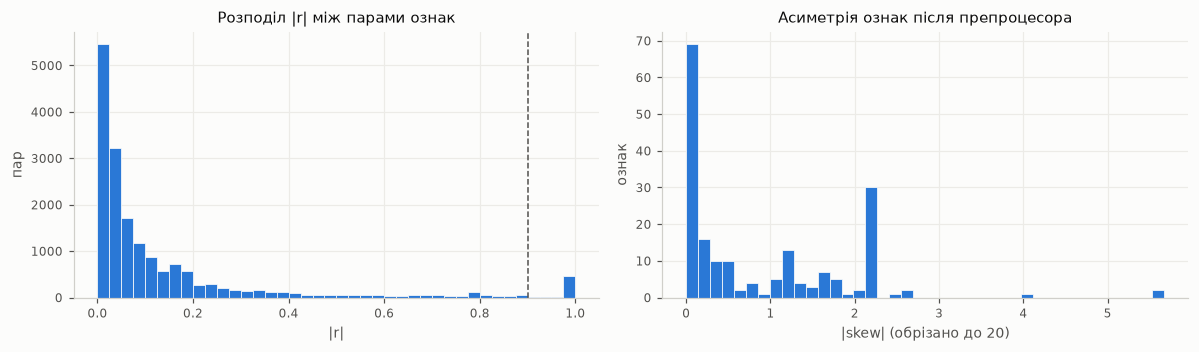

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
corr_abs = Z_train.corr().abs().where(np.triu(np.ones((Z_train.shape[1],) * 2, dtype=bool), k=1)).stack()
axes[0].hist(corr_abs, bins=40, color=ACCENT, edgecolor=SURFACE, linewidth=0.5)
axes[0].axvline(sel_cfg["basic_stats"]["high_corr_threshold"], color=MUTED, linestyle="--", linewidth=1)
axes[0].set_title("Розподіл |r| між парами ознак"); axes[0].set_xlabel("|r|"); axes[0].set_ylabel("пар")
skew = Z_train.skew().abs().clip(upper=20)
axes[1].hist(skew, bins=40, color=ACCENT, edgecolor=SURFACE, linewidth=0.5)
axes[1].set_title("Асиметрія ознак після препроцесора"); axes[1].set_xlabel("|skew| (обрізано до 20)"); axes[1].set_ylabel("ознак")
fig.tight_layout(); fig.savefig(REPORTS / "lab2_basic_stats.png", bbox_inches="tight"); plt.show()

In [26]:
filt = filter_select(Z_train, y_train, sel_cfg)
vif = vif_table(Z_train[filt.feature.head(sel_cfg["basic_stats"]["vif_top_n"])])
print(f"VIF > {sel_cfg['basic_stats']['vif_threshold']}: {int((vif.VIF > sel_cfg['basic_stats']['vif_threshold']).sum())} з {len(vif)} (серед top-{len(vif)} за Filter)")
vif.head(10).round(2)

VIF > 10.0: 23 з 30 (серед top-30 за Filter)


,feature,VIF
0,CashbackPerOrder,3.319036e+11
1,CashbackAmount / OrderCount,3.319036e+11
2,OrderAmountHikeFromlastYear / Tenure,2.435300e+02
3,Tenure / OrderAmountHikeFromlastYear,2.386100e+02
4,CashbackAmount / WarehouseToHome,1.613400e+02
5,WarehouseToHome / CashbackAmount,1.498200e+02
6,Tenure,1.032900e+02
7,OrderCount / Tenure,8.386000e+01
8,NATURAL_LOGARITHM(Tenure),7.649000e+01
9,OrderCount / CashbackAmount,6.628000e+01


In [27]:
# Явна перевірка «дублікатів за побудовою»
checks = pd.Series({
    "corr(SatisfactionScore, MEAN(reviews.rating))": X3_train["SatisfactionScore"].corr(X3_train["MEAN(reviews.rating)"]),
    "corr(OrderCount, COUNT(reviews))  [Spearman]": X3_train["OrderCount"].corr(X3_train["COUNT(reviews)"], method="spearman"),
    "corr(CashbackPerOrder [ручна], CashbackAmount / OrderCount [DFS])": Z_train["CashbackPerOrder"].corr(Z_train["CashbackAmount / OrderCount"]),
})
checks.round(4).to_frame("r")

,r
"corr(SatisfactionScore, MEAN(reviews.rating))",0.9999
"corr(OrderCount, COUNT(reviews)) [Spearman]",0.9957
"corr(CashbackPerOrder [ручна], CashbackAmount / OrderCount [DFS])",1.0000


**Що показала статистика.**
- Сотні пар майже дублікатів (|r| > 0.9): ознака та її логарифм; прямі й обернені відношення (`a / b` і `b / a`);
  індикатори пропусків GLCM-ознак (усі дорівнюють «у клієнта немає фото»).
- **Дублікати за побудовою** (таблиця вище): `MEAN(reviews.rating)` збігається із `SatisfactionScore` — оцінку відгуку підібрано за
  задоволеністю; `COUNT(reviews)` — монотонна функція `OrderCount`; ручна ознака `CashbackPerOrder` (Крок 1) — та сама величина,
  що й DFS-ознака `CashbackAmount / OrderCount`.
- Звідси екстремальний VIF — тому далі відбір, а не «модель на всіх ознаках».


In [28]:
filt.head(30).round(4)

,feature,score,selected
0,Tenure / OrderCount,0.1322,True
1,Tenure / OrderAmountHikeFromlastYear,0.1306,True
2,OrdersPerTenureMonth,0.1271,True
3,Tenure / WarehouseToHome,0.1213,True
4,Tenure / HourSpendOnApp,0.1164,True
5,WarehouseToHome / Tenure,0.1159,True
6,RecencyRatio,0.1154,True
7,OrderCount / Tenure,0.1154,True
8,Tenure,0.1134,True
9,Tenure / CashbackAmount,0.1130,True


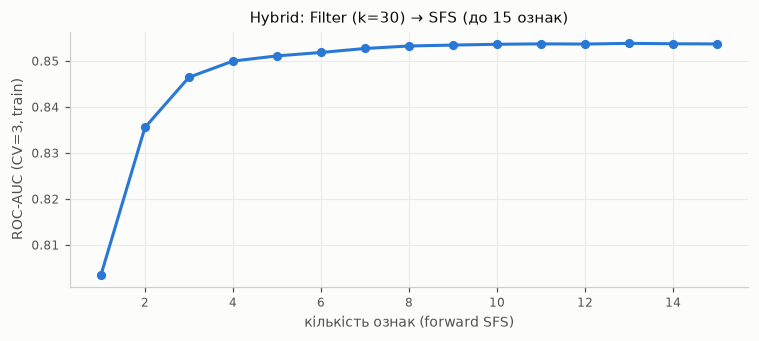

SFS обрав: ['CashbackAmount', 'OrdersPerTenureMonth', 'Segment', 'CashbackAmount / WarehouseToHome', 'DaySinceLastOrder / CashbackAmount', 'DaySinceLastOrder / Tenure', 'OrderCount / Tenure', 'Tenure / CashbackAmount', 'Tenure / CouponUsed', 'Tenure / DaySinceLastOrder', 'Tenure / OrderCount', 'Tenure / WarehouseToHome', 'WarehouseToHome / CashbackAmount', 'WarehouseToHome / Tenure', 'NATURAL_LOGARITHM(CashbackAmount)']


In [29]:
hyb = hybrid_select(Z_train, y_train, sel_cfg)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(hyb["path"].n_features, hyb["path"].cv_roc_auc, color=ACCENT, linewidth=2, marker="o", markersize=5)
ax.set_xlabel("кількість ознак (forward SFS)"); ax.set_ylabel("ROC-AUC (CV=3, train)")
ax.set_title("Hybrid: Filter (k=30) → SFS (до 15 ознак)")
fig.tight_layout(); fig.savefig(REPORTS / "lab2_sfs_path.png", bbox_inches="tight"); plt.show()
print("SFS обрав:", hyb["selected"])

In [30]:
l1 = embedded_l1(Z_train, y_train, sel_cfg)
tree = tree_importance(Z_train, y_train, sel_cfg)
print(f"L1 залишила {int(l1.selected.sum())} ознак з {len(l1)}")
top = 15
selections = {
    "Filter (MI, top-15)": list(filt.feature.head(top)),
    "Hybrid (SFS)": hyb["selected"],
    "Embedded (L1, top-15 |coef|)": list(l1[l1.selected].feature.head(top)),
    "Tree (permutation, top-15)": list(tree.feature.head(top)),
}
comparison = compare_selections(selections)
comparison.to_csv(REPORTS / "lab2_selection_comparison.csv")
comparison.head(20)

L1 залишила 25 ознак з 188


,"Filter (MI, top-15)",Hybrid (SFS),"Embedded (L1, top-15 |coef|)","Tree (permutation, top-15)",votes
WarehouseToHome / Tenure,1,1,1,1,4
OrdersPerTenureMonth,1,1,1,1,4
Tenure,1,0,1,1,3
Tenure / OrderCount,1,1,0,1,3
Segment,0,1,1,1,3
Tenure / WarehouseToHome,1,1,0,1,3
Tenure / OrderAmountHikeFromlastYear,1,0,0,1,2
CashbackAmount,0,1,0,1,2
NumberOfAddress,0,0,1,1,2
Complain,0,0,1,1,2


In [31]:
tree.head(10).round(4)

,feature,perm_importance,perm_std,gini_importance
0,Complain,0.0151,0.0024,0.0194
1,NumberOfAddress,0.0093,0.0012,0.0204
2,Tenure / WarehouseToHome,0.0058,0.0017,0.0195
3,Tenure,0.0047,0.0032,0.0344
4,Tenure / OrderAmountHikeFromlastYear,0.0045,0.0024,0.0316
5,Tenure / OrderCount,0.0042,0.0024,0.0257
6,Segment,0.0041,0.0006,0.0199
7,TenureStage,0.0036,0.0027,0.0277
8,NumberOfDeviceRegistered,0.0025,0.0004,0.0079
9,OrdersPerTenureMonth,0.0025,0.0024,0.0243


## Підсумок

- Таблиця експериментів — `reports/lab2_experiments.csv`, DPR/EOR — `reports/lab2_fairness_citytier.csv`, графіки — `reports/lab2_*.png`.
- Інтерпретація результатів і REFORMS (модулі 3, 4, 6) — `docs/lab2_report.md`.
